# Feature Engineering Practice - UCI Wine Quality Dataset

**Data source:** P. Cortez, A. Cerdeira, F. Almeida, T. Matos and J. Reis. *Modeling wine preferences by data mining from physicochemical properties.* Decision Support Systems, 2009. Hosted at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/186/wine+quality).

This notebook uses the **red wine** subset: 1,599 samples, 11 physicochemical input features (all numeric - no categorical encoding needed here), and a `quality` score (0–10, integer) as the target.

This dataset is a good fit for practicing:
- Viewing and understanding a new dataset
- Spotting skew and applying log transforms
- Building a baseline linear regression model
- Adding **polynomial features** (by hand and with `sklearn`) and checking whether they actually improve the model

Cells marked `# TODO` are for you to complete - commented hints sit just below each one.

**Libraries used:** `pandas`, `matplotlib`, `seaborn`, `scikit-learn`

## 1. Setup & Load the Data

In [27]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
%matplotlib inline

The UCI file is semicolon-delimited (not comma), so we need `sep=";"`.

In [46]:
url_r = "https://raw.githubusercontent.com/mlflow/mlflow/master/tests/datasets/winequality-red.csv"
url_w = "https://raw.githubusercontent.com/mlflow/mlflow/master/tests/datasets/winequality-white.csv"
df_r = pd.read_csv(url_r, sep=";")
df1_w = pd.read_csv(url_w, sep=";")

df = pd.concat([df_r, df1_w], ignore_index=True)

print("Shape:", df.shape)
df.head()

Shape: (6497, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 2. Viewing and Understanding the Dataset

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 609.2 KB


In [54]:

stats_df = df.describe()
stats_df.loc['range'] = stats_df.loc['max'] - stats_df.loc['min']
stats_df.T

,count,mean,std,min,25%,50%,75%,max,range
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000,12.10000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000,1.50000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000,65.20000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100,0.60200
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000,288.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000,434.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898,0.05187
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000,1.29000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000,1.78000


**TODO:** Just from `.info()` and `.describe()`, answer:
1. Are there any missing values?
2. Which columns have the widest range relative to their mean (i.e., might benefit from scaling later)?
3. `quality` is our target - what does its min/max/mean tell you about the range of scores in this dataset?

In [ ]:
# TODO: your observations here

**Observations**
1. No Missing values, every column show 6497 non-null entries, maching the row count.
2. `total sulfur dioxide` and `free sulfur dioxide` have the widest ranges relative to their (max values many times the mean), So they're likely candidates for scalling before any distance-based model, and possibly for log transforms given the skew we'll check next.
3. `quakity` ranges from 3 to 8 (not the full 0-10 scale), with a mean around 5.6 - most wines cluster in the middle of the scale, and nether best nor worst possible scores appear in this dataset at all.

### Visualizing the target: `quality`

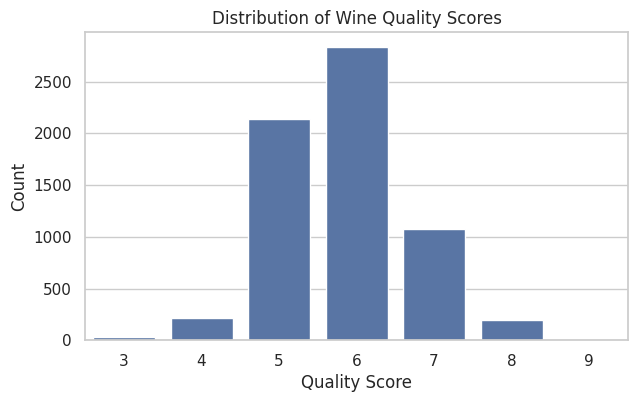

In [55]:
plt.figure(figsize=(7, 4))
sns.countplot(x="quality", data=df, color="#4C72B0")
plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Count")
plt.show()

**TODO:** What do you notice about the distribution of `quality`? Is it balanced across scores, or concentrated around a few values? How might that affect a regression model trained on it?

In [ ]:
# TODO: your observations here


**Observations:** the distribution is strongly concentrated on scores 5 and 6, with much smaller counts at the extremes (3, 4, 7, 8). This imbalance means a regression model will see far more examples of "average" wine than of very good or very bad wine, so it will likely be more accurate for mid-range quality scores and less reliable at the extremes, where it has little data to learn from.

## 3. Checking for Skew

Skewed features can hurt linear regression's assumptions, just like we saw with the Ames Housing data. Let's check the skew of every numeric column.

In [56]:
skew_vals = df.skew().sort_values(ascending=False)
skew_vals

,0
chlorides,5.399828
sulphates,1.797270
fixed acidity,1.723290
volatile acidity,1.495097
residual sugar,1.435404
free sulfur dioxide,1.220066
alcohol,0.565718
density,0.503602
citric acid,0.471731
pH,0.386839


**TODO:** Using a `skew_limit` of `0.75` (same threshold we used for Ames Housing), filter `skew_vals` down to just the columns that exceed this limit (in absolute value). Store the result in `skew_cols`.

In [33]:
# TODO: filter skew_vals to columns where abs(skew) > skew_limit
skew_limit = 0.75

skew_cols = None  # replace None
# skew_cols

In [57]:
skew_limit = 0.75
skew_cols = (
    skew_vals.sort_index(ascending=False)
    .to_frame()
    .rename(columns={0 : "Skew" })
    .query("abs(Skew) > @skew_limit")
)

skew_cols

,Skew
volatile acidity,1.495097
sulphates,1.797270
residual sugar,1.435404
free sulfur dioxide,1.220066
fixed acidity,1.723290
chlorides,5.399828


**TODO:** Pick one skewed column from your `skew_cols` result (e.g. `"chlorides"` or `"residual sugar"`) and plot its distribution before and after a `np.log1p` transform, side by side - same approach we used for `BsmtFin SF 1` in the Ames notebook.

In [14]:
# TODO: before/after log1p plot for one skewed column
field = None  # e.g. "chlorides"

# fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(10, 4))
# df[field].hist(ax=ax_before, bins=30, color="#DD8452")
# ax_before.set(title="Before np.log1p", xlabel="Value", ylabel="Frequency")
# df[field].apply(np.log1p).hist(ax=ax_after, bins=30, color="#55A868")
# ax_after.set(title="After np.log1p", xlabel="Value", ylabel="Frequency")
# plt.show()

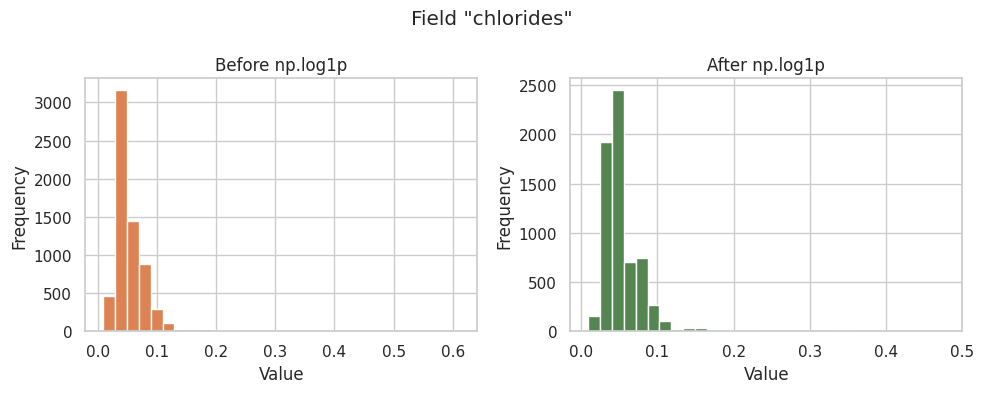

In [58]:
field = "chlorides"
fig, (ax_before, ax_after) = plt.subplots(1,2, figsize=(10,4))

df[field].hist(ax=ax_before, bins=30, color="#DD8252")
ax_before.set(title="Before np.log1p", ylabel="Frequency", xlabel="Value")

df[field].apply(np.log1p).hist(ax=ax_after, bins=30, color="#558652")
ax_after.set(title="After np.log1p", ylabel="Frequency", xlabel="Value")

fig.suptitle(f'Field "{field}"')
fig.tight_layout()
plt.show()

**TODO:** Apply `np.log1p` to every column in `skew_cols` (skip `quality` if it happens to appear, since that's our target) and store the result in a new dataframe `df_transformed`.

In [ ]:
# TODO: log-transform the skewed columns
df_transformed = df.copy()

# for col in skew_cols.index:
#     if col == "quality":
#         continue
#     df_transformed[col] = df_transformed[col].apply(np.log1p)

In [59]:
df_transformed = df.copy()
for col in skew_cols.index:
    if col == "quality":
        continue
    df_transformed[col] = df_transformed[col].apply(np.log1p)
    
df_transformed[skew_cols.index].skew()

,0
volatile acidity,1.126873
sulphates,1.098588
residual sugar,0.414917
free sulfur dioxide,-0.721434
fixed acidity,0.976702
chlorides,4.484421


## 4. Pair Plot & Correlations

With 11 features, a full pair plot can get crowded:  
let's first check correlations with `quality` to pick a few of the most relevant features to visualize closely.

In [60]:
corr_with_quality = df.corr()["quality"].drop("quality").sort_values(ascending=False)
corr_with_quality

,quality
alcohol,0.444319
citric acid,0.085532
free sulfur dioxide,0.055463
sulphates,0.038485
pH,0.019506
residual sugar,-0.036980
total sulfur dioxide,-0.041385
fixed acidity,-0.076743
chlorides,-0.200666
volatile acidity,-0.265699


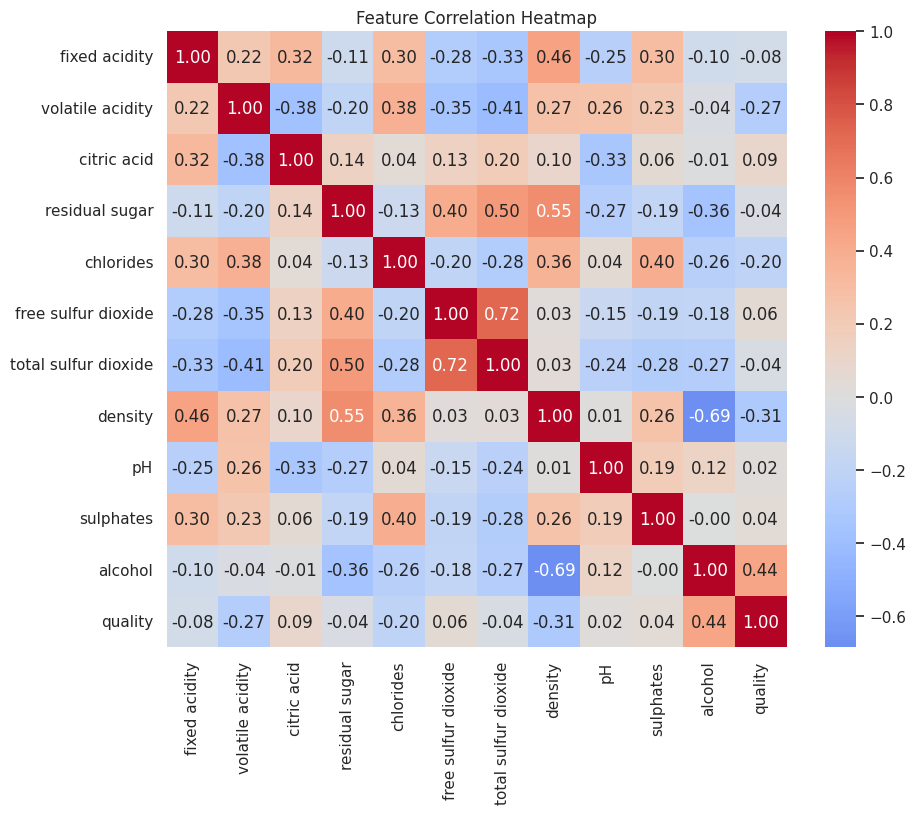

In [61]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.show()

**TODO:** Based on the correlation values, pick the 3 - 4 features most strongly correlated (positively or negatively) with `quality` and generate a `sns.pairplot()` using just those columns plus `quality`.

In [ ]:
# TODO: pairplot on the most relevant features
top_features = []  # e.g. ["alcohol", "volatile acidity", "sulphates", "quality"]

# sns.pairplot(df[top_features], plot_kws=dict(alpha=0.3, edgecolor="none"))
# plt.show()

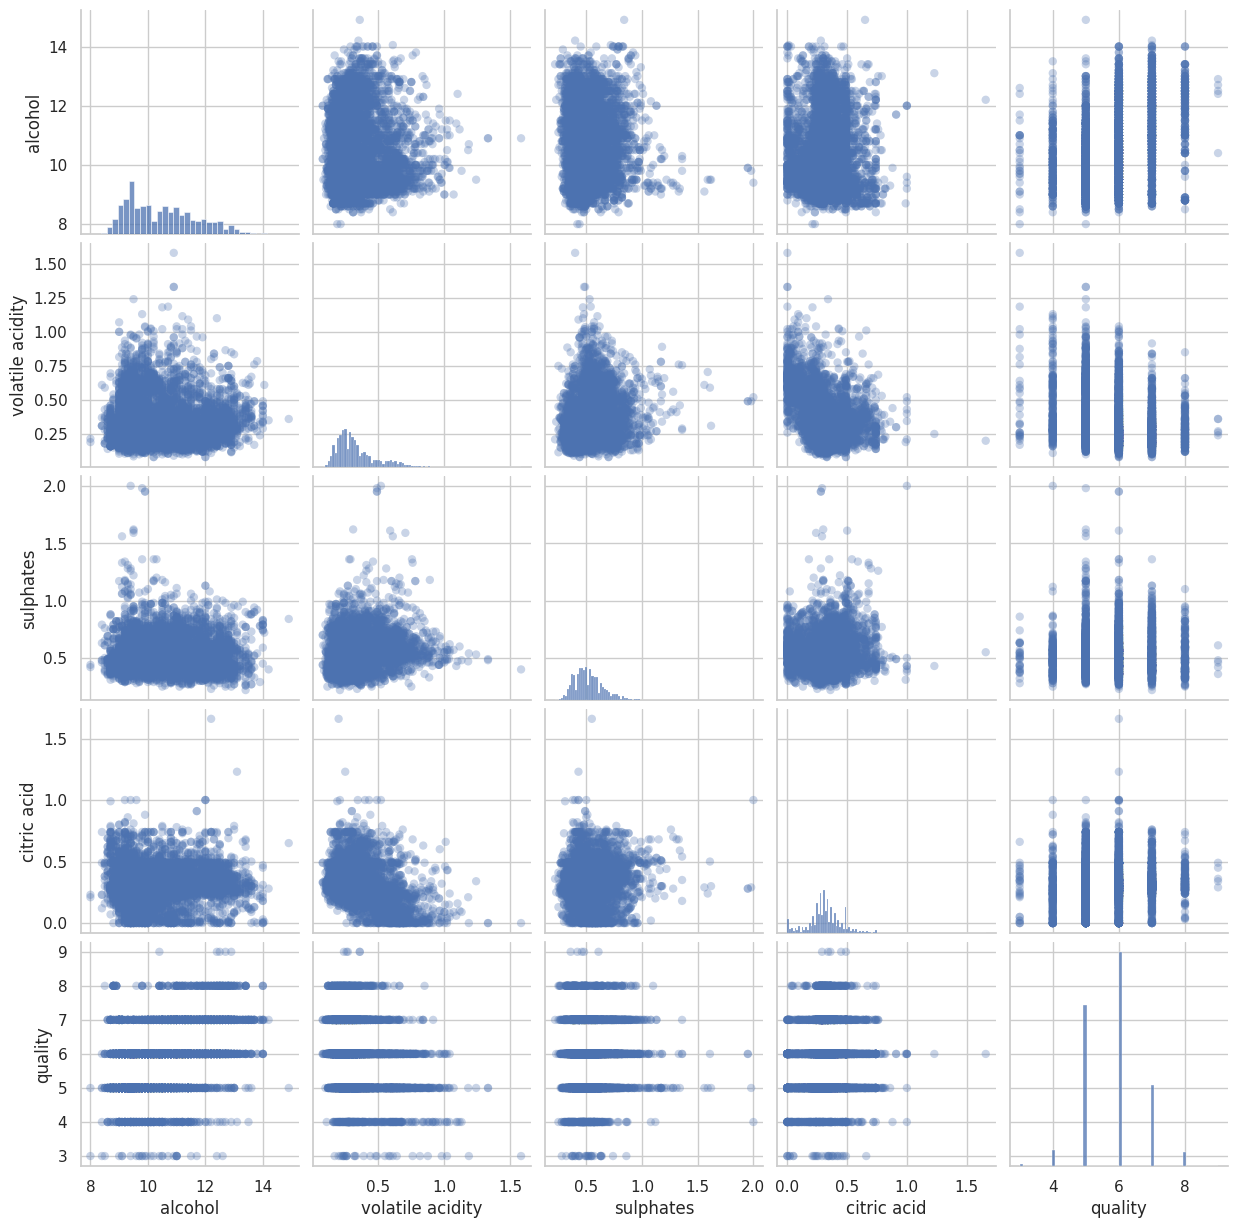

In [62]:
top_features = ["alcohol", "volatile acidity", "sulphates", "citric acid", "quality"]
sns.pairplot(df[top_features], plot_kws=dict(alpha=0.3, edgecolor="none"))
plt.show()

**TODO:** Looking at the scatter plots against `quality`, do any relationships look curved rather than linear? Those are good candidates for polynomial terms in the next section.

## 5. Baseline Model

Let's separate features from the target and build a reusable train/score function, same pattern as the Ames notebook.

In [63]:
X = df.drop(columns=["quality"])
y = df["quality"]

X.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4


In [64]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

def split_fit_score(X, y, test_size=0.3, random_state=42):
    """Split data, fit a linear regression model, and report train/validation R^2 and RMSE."""
    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    train_r2 = r2_score(y_train, model.predict(X_train))
    val_r2 = r2_score(y_val, model.predict(X_val))
    val_rmse = mean_squared_error(y_val, model.predict(X_val)) ** 0.5

    print(f"Train R^2:      {train_r2:.4f}")
    print(f"Validation R^2: {val_r2:.4f}")
    print(f"Validation RMSE: {val_rmse:.4f}")

    return model, train_r2, val_r2

In [66]:
baseline_model, baseline_train_r2, baseline_val_r2 = split_fit_score(X, y)

Train R^2:      0.2999
Validation R^2: 0.2701
Validation RMSE: 0.7298


## 6. Adding Polynomial Features (By Hand)

**TODO:** Pick 1 - 2 features you flagged earlier as having a curved relationship with `quality` (from Section 4). Create a copy of `X` called `X2`, and add a squared term for each (e.g. `X2["alcohol2"] = X2["alcohol"] ** 2`). Then run `split_fit_score(X2, y)` and compare the validation R² to the baseline.

In [ ]:
# TODO: add squared terms for 1-2 features
X2 = X.copy()

# X2["alcohol2"] = X2["alcohol"] ** 2

# poly_model, poly_train_r2, poly_val_r2 = split_fit_score(X2, y)


In [67]:
X2 = X.copy()

X2["alcohol2"] = X2["alcohol"] ** 2
X2["volatile_acidity2"] = X2["volatile acidity"] ** 2

poly_model, poly_train_r2, poly_val_r2 = split_fit_score(X2, y)


Train R^2:      0.3045
Validation R^2: 0.2689
Validation RMSE: 0.7304


**TODO:** Try adding an interaction term between two features you think might combine to affect quality (e.g. `alcohol` × `sulphates`, or `volatile acidity` × `citric acid`). Store the result in `X3` and score it.

In [ ]:
# TODO: add an interaction term
X3 = X2.copy()

# X3["alcohol_x_sulphates"] = X3["alcohol"] * X3["sulphates"]

# interaction_model, interaction_train_r2, interaction_val_r2 = split_fit_score(X3, y)

In [68]:
X3 = X2.copy()

X3["alcohol_x_sulphates"] = X3["alcohol"] * X3["sulphates"]
interaction_model, interaction_train_r2, interaction_val_r2 = split_fit_score(X3, y)

Train R^2:      0.3047
Validation R^2: 0.2681
Validation RMSE: 0.7307


## 7. Polynomial Features with Scikit-Learn

Rather than adding terms one at a time, `sklearn`'s `PolynomialFeatures` can generate every combination of features up to a given degree automatically - including all pairwise interactions.

**TODO:** Using `PolynomialFeatures(degree=2)`, transform just 2 - 3 of your top features (not the whole `X` - with 11 features, `degree=2` would generate dozens of columns) and inspect the resulting column names with `get_feature_names_out()`.

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# TODO: choose 2-3 features and generate degree-2 polynomial terms
poly_features = []  # e.g. ["alcohol", "sulphates"]

# pf = PolynomialFeatures(degree=2)
# pf.fit(df[poly_features])
# feat_array = pf.transform(df[poly_features])
# poly_feature_names = pf.get_feature_names_out(input_features=poly_features)
# pd.DataFrame(feat_array, columns=poly_feature_names).head()

In [69]:
from sklearn.preprocessing import PolynomialFeatures

# choose 2-3 features and generate degree-2 polynomial terms
poly_features = ["alcohol", "sulphates", "volatile acidity"]  

pf = PolynomialFeatures(degree=2)
pf.fit(df[poly_features])
feat_array = pf.transform(df[poly_features])
poly_feature_names = pf.get_feature_names_out(input_features=poly_features)
pd.DataFrame(feat_array, columns=poly_feature_names).head()

,1,alcohol,sulphates,volatile acidity,alcohol^2,alcohol sulphates,alcohol volatile acidity,sulphates^2,sulphates volatile acidity,volatile acidity^2
0,1.0,9.4,0.56,0.70,88.36,5.264,6.580,0.3136,0.3920,0.4900
1,1.0,9.8,0.68,0.88,96.04,6.664,8.624,0.4624,0.5984,0.7744
2,1.0,9.8,0.65,0.76,96.04,6.370,7.448,0.4225,0.4940,0.5776
3,1.0,9.8,0.58,0.28,96.04,5.684,2.744,0.3364,0.1624,0.0784
4,1.0,9.4,0.56,0.70,88.36,5.264,6.580,0.3136,0.3920,0.4900


**TODO:** Build a new feature set `X4` that combines your original features with the sklearn-generated polynomial terms above (drop the duplicate `1` intercept and original linear-term columns `PolynomialFeatures` re-generates, since `X` already has those). Score it with `split_fit_score`.

*Hint:* you can concatenate the new squared/interaction columns onto a copy of `X` with `pd.concat`, matching on index.

In [ ]:
# TODO: combine original features with new polynomial terms, then score
X4 = X.copy()

# poly_df = pd.DataFrame(feat_array, columns=poly_feature_names, index=df.index)
# new_cols = [c for c in poly_feature_names if c not in ["1"] + poly_features]
# X4 = pd.concat([X4, poly_df[new_cols]], axis=1)

# full_poly_model, full_poly_train_r2, full_poly_val_r2 = split_fit_score(X4, y)

In [70]:
X4 = X.copy()

poly_df = pd.DataFrame(feat_array, columns=poly_feature_names, index=df.index)
new_cols = [c for c in poly_feature_names if c not in ["1"] + poly_features]
X4 = pd.concat([X4, poly_df[new_cols]], axis=1)

full_poly_model, full_poly_train_r2, full_poly_val_r2 = split_fit_score(X4, y)

Train R^2:      0.3076
Validation R^2: 0.2698
Validation RMSE: 0.7299


## 8. Comparing Results

**TODO:** Collect the validation R² from each feature set you tried (baseline, hand-built polynomial, interaction, sklearn polynomial) into a small comparison table or bar chart. Which feature set performed best on the *validation* set — not just the training set?

In [ ]:
# TODO: build a comparison, e.g.
# results = pd.DataFrame({
#     "Feature Set": ["Baseline", "Hand Poly", "Hand Interaction", "Sklearn Poly"],
#     "Validation R^2": [baseline_val_r2, poly_val_r2, interaction_val_r2, full_poly_val_r2],
# })
# results

# plt.figure(figsize=(7, 4))
# sns.barplot(x="Feature Set", y="Validation R^2", data=results, color="#4C72B0")
# plt.title("Validation R^2 by Feature Set")
# plt.ylim(0, 1)
# plt.show()

In [71]:
results = pd.DataFrame({
    "Feature Set": ["Baseline", "Hand Poly", "Hand Interaction", "Sklearn Poly"],
    "Train R^2": [baseline_train_r2, poly_train_r2, interaction_train_r2, full_poly_train_r2],
    "Validation R^2": [baseline_val_r2, poly_val_r2, interaction_val_r2, full_poly_val_r2],
})
results

,Feature Set,Train R^2,Validation R^2
0,Baseline,0.299875,0.270090
1,Hand Poly,0.304512,0.268935
2,Hand Interaction,0.304687,0.268139
3,Sklearn Poly,0.307551,0.269834


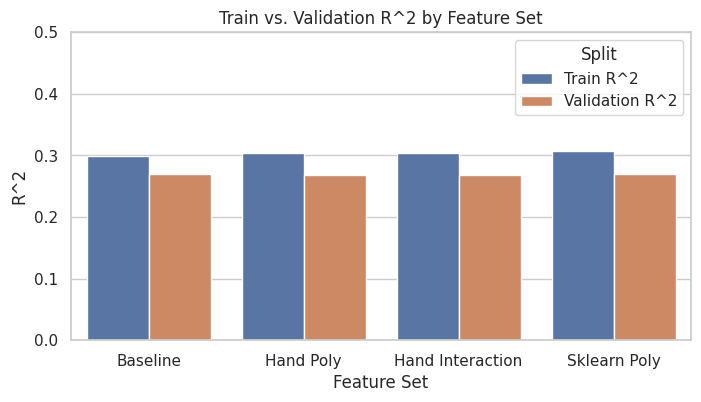

In [72]:
plt.figure(figsize=(8, 4))
results_melted = results.melt(id_vars="Feature Set", var_name="Split", value_name="R^2")
sns.barplot(x="Feature Set", y="R^2", hue="Split", data=results_melted)
plt.title("Train vs. Validation R^2 by Feature Set")
plt.ylim(0, 0.5)
plt.show()

## 9. Wrap-Up

**TODO:** In a markdown cell below, summarize:
1. Which features had the strongest raw correlation with `quality`?
2. Did log-transforming skewed features seem likely to help, based on what you saw in Section 3?
3. Did adding polynomial/interaction terms actually improve validation R², or did it mainly help (or hurt) the training score? What does that tell you about overfitting?
4. If you kept adding more polynomial terms, what would you expect to happen to the gap between train and validation performance?

In [ ]:
# TODO: final summary (as a markdown cell or comments)